# CHURN ANALYSIS

In [398]:
#import libraries

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [399]:
# import database
conn = sqlite3.connect('customer_churn.db')

sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
"""

tables = pd.read_sql(sql_query, conn)

#create dataframe
for table_name in tables['name']:
    df= pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"] = df
    print(f"Created dataframe: df_{table_name}")

conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [400]:
# data cleaning

In [401]:
df_db_customer.tail(5)

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,None,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,None,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,None,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,None,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,None,None


In [402]:
df_db_customer.info() #check for nulls

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [403]:
#a. DROP COLUMNS = interest , pincode
#b. RENAME COLUMNS -name
#c. CHANGE DATA TYPES
#d. FIX MISSING VALUES
#e. STANDARDISE GENDER - WOMEN , FEMALE, MALE, MEN??


In [404]:
#b. RENAME COLUMNS -name
df_db_customer.rename(columns = {'name':'customer_name'},inplace = True)

In [405]:
#a. DROP COLUMNS = interest , pincode
df_db_customer.drop(columns=['interests','pincode'],inplace = True)


In [406]:
#c. CHANGE DATA TYPES
df_db_customer['dob']= pd.to_datetime(df_db_customer['dob'])

In [407]:
df_db_customer.head()

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05


In [408]:
#e. STANDARDISE GENDER - WOMEN , FEMALE, MALE, MEN??
# df_db_customer['gender'].unique()


df_db_customer['gender']= df_db_customer['gender'].replace({'Men':'Male', 'Women':'Female'})

In [409]:
#d. FIX MISSING VALUES
df_db_customer[df_db_customer['country'].isnull()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,None,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,None,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01


In [410]:
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country']= df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [411]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


In [412]:
date_col = ['subscription_start_date','renewal_date','cancellation_date']

df_db_subscription[date_col]= df_db_subscription[date_col].apply(pd.to_datetime)

df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


In [413]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      object
 1   complaint_date  9 non-null      object
 2   escalations     9 non-null      object
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      object
dtypes: int64(1), object(5)
memory usage: 564.0+ bytes


In [414]:
df_db_support = df_db_support.drop(df_db_support.columns[-2:], axis = 1 )

In [415]:
df_db_support['complaint_date']= pd.to_datetime(df_db_support['complaint_date'])

In [416]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30


In [417]:
#Feature Engineering

#create new columns using existing columns 

df_db_subscription['churn_flag']= np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [418]:
df_db_support['customerid'].size

9

In [419]:
df_db_support['complaint_count']= df_db_support.groupby('customerid')['customerid'].transform('count')

In [420]:
df_db_support= df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep='last')

In [421]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1
4,0013-SMEOE,2024-11-01,N,30,1
3,0013-MHZWF,2025-03-18,N,90,1


In [422]:
df= (df_db_subscription
    .merge(df_db_customer, on='customerid',how='left')
    .merge(df_db_support, on='customerid',how='left'))

In [423]:
df.shape

(21, 21)

In [424]:
df.to_csv('exported_churn_data.csv', index = False)

In [425]:
# Data Analysis

In [426]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [427]:
#1.Churn_rate
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate =",round(churn_rate,2) ,"%")

Churn Rate = 28.57 %


In [428]:
#2.Retention_rate
retention_rate = 100 - churn_rate
print("Retention Rate =",round(retention_rate,2) ,"%")

Retention Rate = 71.43 %


In [429]:
#3.Churn rate by Plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))

print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [430]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [431]:
#4. Churn by state + sum (revenue) & count of users
churn_by_state = (df.groupby('state')
    .agg(
        total_churn=('churn_flag', 'mean'),
        total_revenue=('monthly_charges', 'sum'),
        user_count=('churn_flag', 'count'),  # or use any other non-null column
    )
    .reset_index()
)

churn_by_state.head()

#4b. Churn by subscrpition

churn_by_subscription = (df.groupby('subscription_type')
    .agg(
         total_churn= ('churn_flag' , 'mean'),
        total_revenue=('monthly_charges', 'sum'),
        user_count=('churn_flag', 'count'),
    )
    .reset_index()
)  

churn_by_subscription.head()

,subscription_type,total_churn,total_revenue,user_count
0,Organic,0.000000,145.91,9
1,Paid,0.166667,174.94,6
2,Refferal,0.833333,74.94,6


In [432]:
#5 ARPU (Average Revenue per user)
arpu = df['monthly_charges'].mean()
print("ARPU = ",round(arpu ,2) ,"%")

ARPU =  18.85 %


In [433]:
#6 customer age
today = pd.Timestamp.today()

df['age']= today.year - df['dob'].dt.year

avg_age = df['age'].mean()
print(round(avg_age))

37


In [434]:
#7 AVERGAE CUSTOMER TENURE (count of days b/w start date and end date)

today = pd.Timestamp.today()

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(), 
    (df['cancellation_date']- df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()

print("Average Tenure Date = ", round(avg_tenure))

Average Tenure Date =  1566


In [435]:
##8 revnue loss
revenue_at_risk= df.loc[df['churn_flag']==1,'monthly_charges'].sum()
print("Revenue at risk (CAD 'K') = ", round(revenue_at_risk))

Revenue at risk (CAD 'K') =  74


In [436]:
#9 Escalation rate
escalation_rate = (df['escalations']=='Y').mean()*100
print("Escalation Rate = ", round(escalation_rate,2),"%")

Escalation Rate =  19.05 %


In [437]:
#10 avgerage complaint rate 

avg_complaint= df['complaint_count'].sum()/df['customerid'].nunique()

print("Average Complaint Per User", round(avg_complaint,2))

Average Complaint Per User 0.43


In [440]:
df['escalations'] = (
    df['escalations']
    .astype(str)
    .str.strip()
    .str.upper()
    .replace({'Y': 1})
    .replace(['N', 'NAN'], 0)
    .astype(int)
)

# Check the raw value counts of the column
print(df['escalations'].value_counts(dropna=False))

escalations
0    17
1     4
Name: count, dtype: int64


In [443]:
corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])

print("Correlation b/w Escalation and churn flag is = " ,round(correlation,2))

Correlation b/w Escalation and churn flag is =  0.77


In [447]:
#11. Churn Risk

conditions = [
    (df['churn_score'] <50),
    (df['churn_score'] >=50) & (df['churn_score'] <70),
    (df['churn_score'] >=70)
]

choices = ['low','med','high']

df['churn_risk'] = np.select(conditions,choices,default='unknown')

df[['churn_score','churn_risk']].head()

,churn_score,churn_risk
0,12,low
1,91,high
2,34,low
3,8,low
4,88,high


In [463]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,age,tenure_days,churn_risk
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,Maharashtra,Male,1982-04-12,NaT,0,NaN,NaN,44,2047.0,low
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,2.0,31,1501.0,high
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,Delhi,Female,1978-02-15,NaT,0,NaN,NaN,48,1432.0,low
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,Nagaland,Male,2001-08-30,NaT,0,NaN,NaN,25,2722.0,low
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,Delhi,Female,1990-05-05,2024-01-20,1,20.0,1.0,36,419.0,high


In [448]:
# Data Visualization 

In [464]:
df_visual= df.copy()
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk'],
      dtype='object')

In [465]:
print(df_visual['cancellation_date'].dtype)

datetime64[ns]


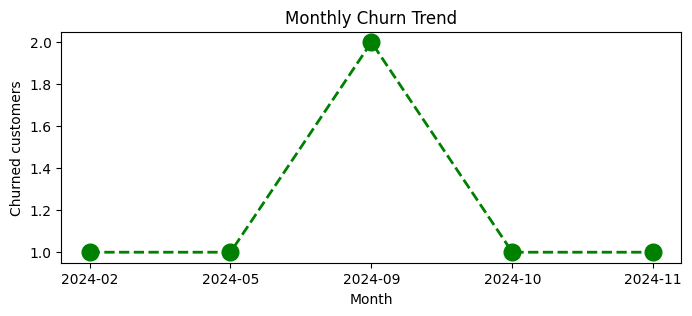

In [469]:
# 1. Prepare the monthly churn trend data
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = (
    df_visual[df_visual['churn_flag'] == 1]
    .groupby('cancellation_month')
    .size()
)

# 2. Plot the chart with corrected parameters
plt.figure(figsize=(8, 3))
plt.plot(
    churn_trend.index.astype(str),
    churn_trend.values,
    color='green',
    marker='o',
    linestyle='dashed',
    linewidth=2,
    markersize=12,
)
plt.title ('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned customers')
plt.show()

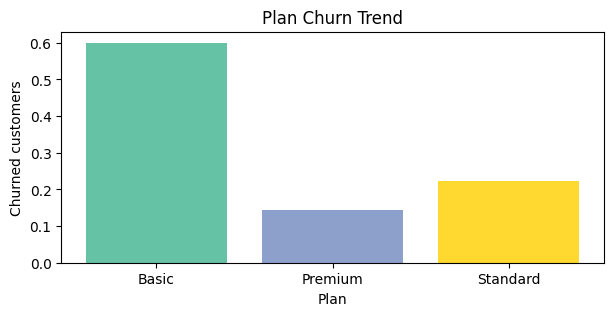

In [486]:
# Churn bY Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

colors = [plt.cm.Set2(i / len(churn_plan)) for i in range(len(churn_plan))]
plt.figure(figsize=(7, 3))

plt.bar(churn_plan.index, churn_plan.values, color= colors)

plt.title ('Plan Churn Trend')
plt.xlabel('Plan')
plt.ylabel('Churned customers')
plt.show()



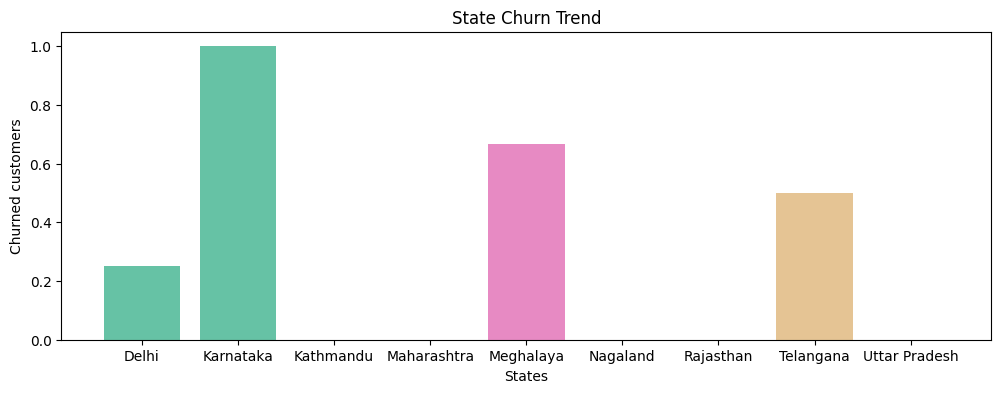

In [490]:
# Churn by state

churn_state = df_visual.groupby('state')['churn_flag'].mean()

colors = [plt.cm.Set2(i / len(churn_state)) for i in range(len(churn_state))]
plt.figure(figsize=(12,4))

plt.bar(churn_state.index, churn_state.values, color= colors)

plt.title ('State Churn Trend')
plt.xlabel('States')
plt.ylabel('Churned customers')
plt.show()




In [ ]:
# Visualization using Seaborn

In [491]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [497]:
df_visual[[ 'plan_type', 'contract_type',  'churn_score','churn_flag', 'escalations','churn_risk']].head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,Standard,Annual,12,0,0,low
1,Premium,Annual,91,1,1,high
2,Basic,Monthly,34,0,0,low
3,Premium,Annual,8,0,0,low
4,Standard,Monthly,88,1,1,high


In [499]:
import warnings
warnings.filterwarnings("ignore")

#encoding-convert struing to numeric to find correlation
df_encoded = df_visual[[ 'plan_type', 'contract_type',  'churn_score','churn_flag', 'escalations','churn_risk']]

# 2. Define your exact ordinal order mappings
order_mappings = {
    'plan_type': ['Basic', 'Standard', 'Premium'],  # Note: fixed typo 'Standrad'
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high'],
}

# 3. Apply Categorical encoding properly
for col, order in order_mappings.items():
  # Convert to categorical with explicit ordered categories, then extract codes (.codes)
  df_encoded[col] = pd.Categorical(
      df_encoded[col], categories=order, ordered=True
  ).codes

# 4. View your encoded dataframe head
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,1,1,12,0,0,0
1,2,1,91,1,1,2
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,1,2


<Axes: >

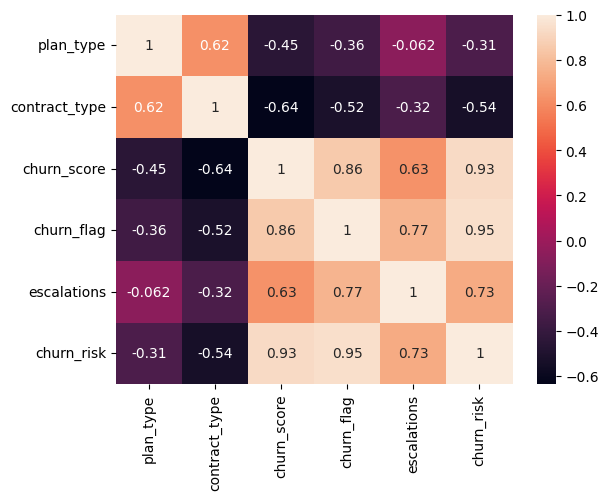

In [500]:
#Heatmap(correlation matrix)

sns.heatmap(df_encoded.corr(), annot= True)

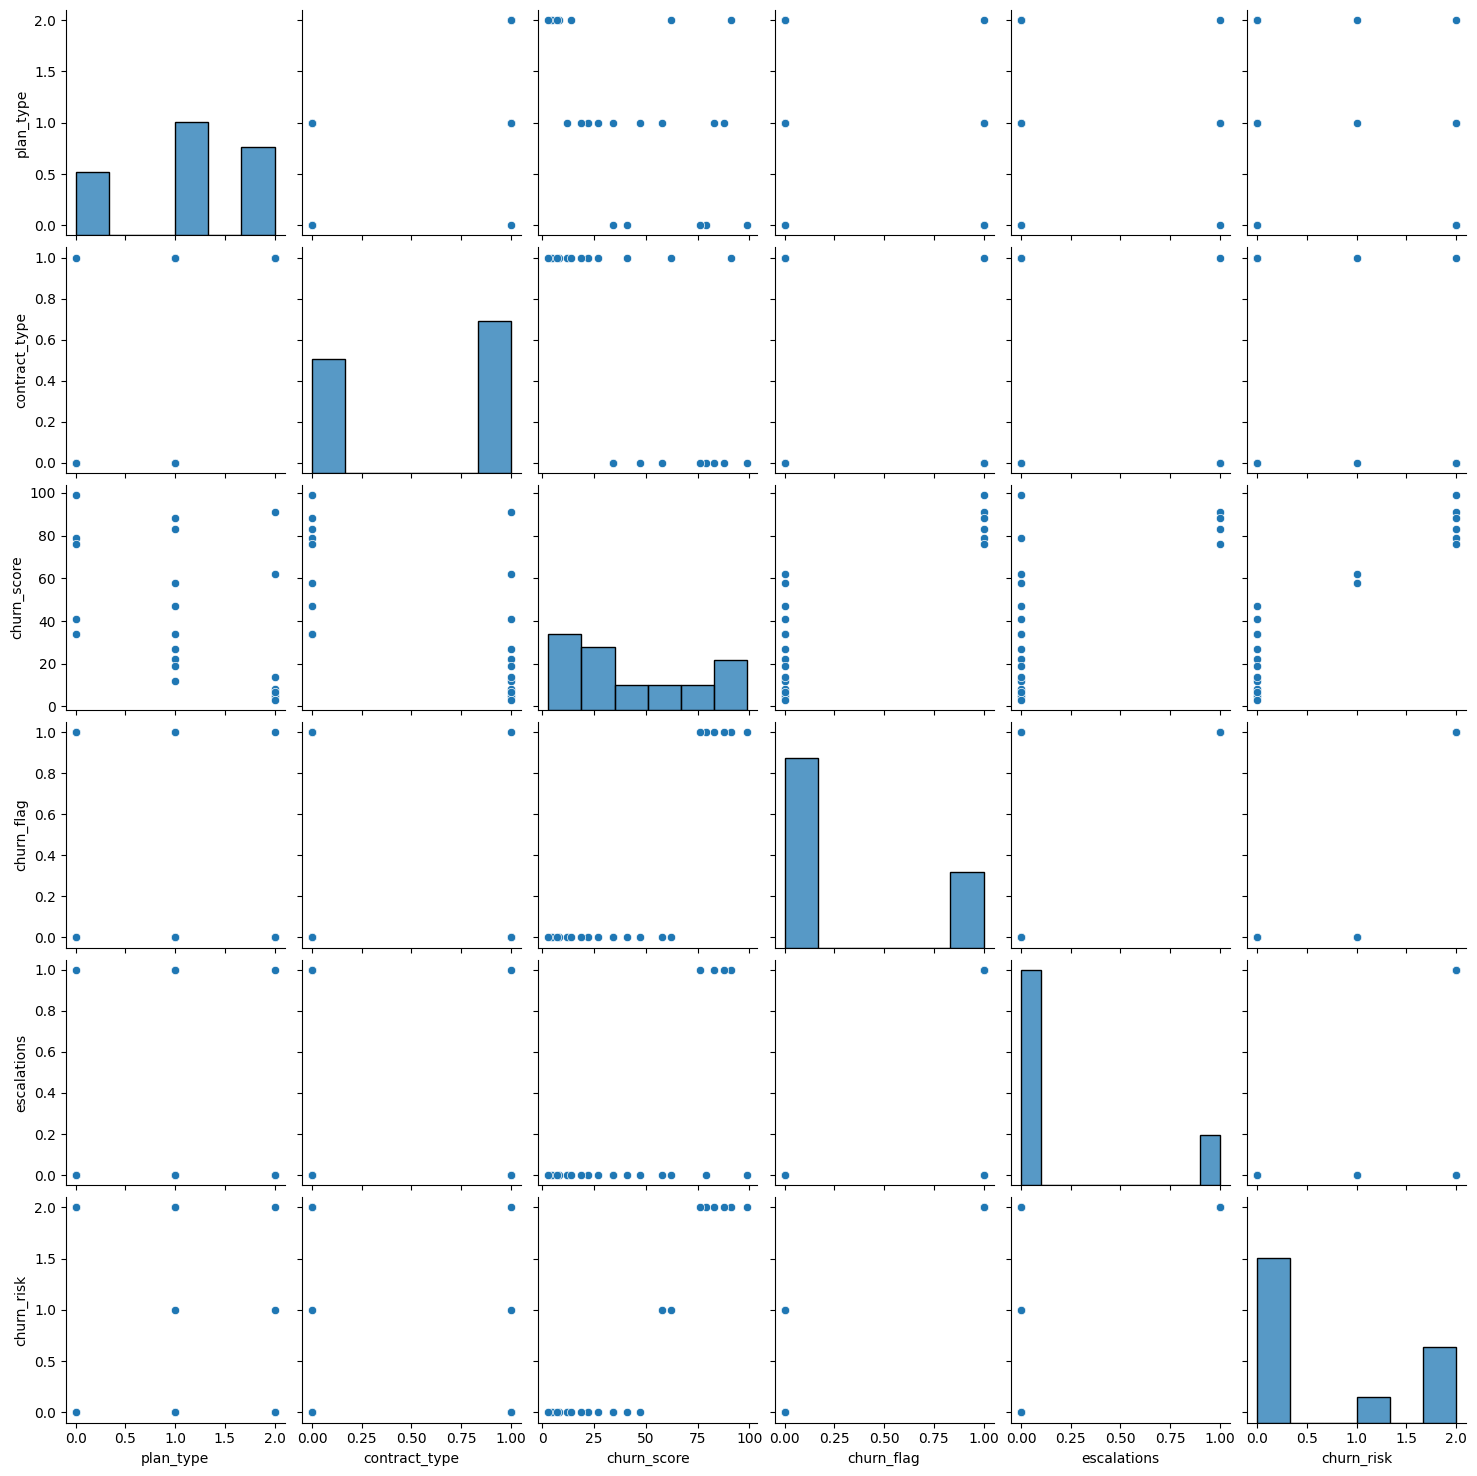

In [501]:
#Pair plot- relationship 

sns.pairplot(df_encoded)

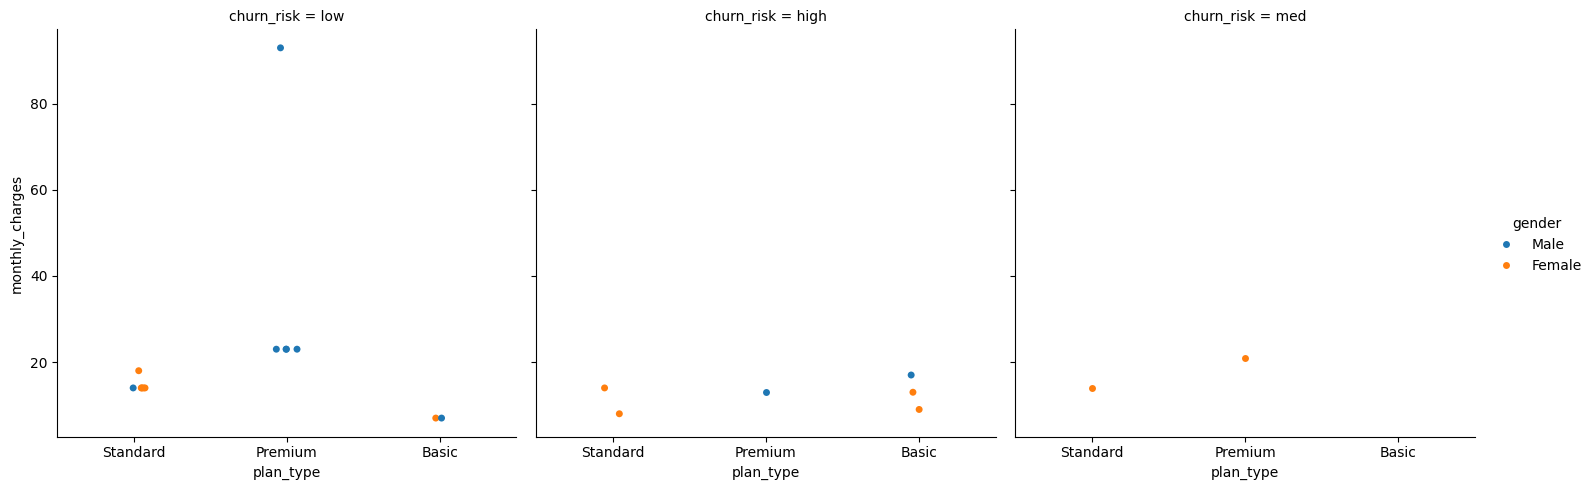

In [503]:
# catplt/Facegrid plt-multi dimenionsan comparison

sns.catplot(data= df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

In [511]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges','customerid','churn_flag'],
    aggfunc = {
        'monthly_charges':'sum',
        'customerid':'nunique',
        'churn_flag': 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91
